# 05 · Stage 2: switching points from an oscilloscope recording

**Purpose.** Takes one bench recording of a staircase sweep (oscillator output plus Arduino trigger) and finds, for every sweep cycle, the resistance at which the oscillation switched on (reached 90 % of full size) and switched off (fell to 10 %). It also measures the true step time and sweep rate from the recording, and collects every run in a master table.

**In the report.** Chapter 5, Sec. 5.2 (switching points of all 17 rates, Fig. 5.1, Fig. 3.6), Appendix Table A.1. The master table feeds notebooks 06 and 07. The same code analyses the simulated runs of Stage 3 (notebook 09).

## Theory

The amplitude grows while $G > G_c$ and decays while $G < G_c$ (notebook 00). A cycle's **switch-on point** $R_{\rm on}$ is the swept resistance at the moment the envelope first reaches 90 % of full size; its **switch-off point** $R_{\rm off}$ is the resistance when it last falls through 10 %. With a moving threshold both lag behind $R_c$ (Eqs. 2.22, 2.24), which notebook 06 fits.

Configuration A: $R_F = 91\,\mathrm{k\Omega}$ + potentiometer (31 steps of 322.6 Ω), $R_i = 47\,\mathrm{k\Omega}$, so $G = 1 + R_F/R_i$ sweeps 2.94 → 3.15.

## Method

1. **Load** the three-column file (time, trigger, output); rebuild an evenly spaced time axis from the sample index.
2. **$t_0$** = the trigger pulse's falling edge (linear interpolation at half height): the moment the sweep starts.
3. **Oscillation period** from the largest FFT peak above 1 Hz.
4. **Bursts**: a running half peak-to-peak amplitude over two oscillation periods; samples above 5 % of its 99th percentile are "on". Bursts shorter than 10 oscillation periods, or never reaching half the rail, are ignored. The baseline (median of the quiet parts) is subtracted.
5. **Envelope** = running maximum of the positive half-wave over `ENV_WINDOW` (0.15 s). A backward window is exact on rising edges and a forward window on falling edges; their minimum follows both.
6. **Switching times**: $t_{90}$, the first upward crossing of 90 % of the burst's plateau; $t_{10}$, the last downward crossing of 10 %. The 50 % crossings are kept as a cross-check.
7. **Step time**: the sweep period is fitted by least squares to the $t_{90}$ and $t_{10}$ of all cycles together (common slope); $\tau$ = period / 64 and the true rate $\lambda = \Delta R/\tau$.
8. **Resistance**: each event time is converted to resistance with the straight line through the middle of every step (notebook 03), which accumulates the same growth as the staircase. Flags record whether $t_{90}$ fell on the rising part of the sweep and $t_{10}$ on the falling part; only then is the value a real threshold.
9. **High rates (cycle mode)**: if the oscillation never switches off between sweeps, bursts merge. The record is then cut into sweep cycles at the envelope minima, warm-up cycles are skipped, and $t_{10}$ exists only for cycles that really fell below 10 %.
10. **Master table**: one row per cycle, with the run's averages repeated on each row. A run already present is replaced only if its numbers changed.

## Requirements

Python 3.9+, `numpy`, `pandas`, `scipy`, `matplotlib`.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
FILE_NAME      = "../data/stage2/newexpdata - 1kohms.csv"   # three columns by POSITION: time (s), trigger CH2 (V), output CH1 (V)
LAMBDA_NOMINAL = 1000      # nominal rate of this run (ohm/s) = 312.5 / (STEP_DELAY_MS/1000); the run's ID in the master
STEP_DELAY_MS  = 313       # delay() per step in the Arduino sketch (ms)

BATCH = False              # True -> analyse every run listed in BATCH_RUNS instead of FILE_NAME alone
BATCH_FOLDER = "../data/stage2"
BATCH_RUNS = {             # file name -> (nominal rate ohm/s, step delay ms); the 17 runs of the report
    "newexpdata - 100ohms.csv": (100, 3125), "newexpdata - 150ohms.csv": (150, 2083), "newexpdata - 200ohms.csv": (200, 1562),
    "newexpdata - 250ohms.csv": (250, 1250), "newexpdata - 300ohms.csv": (300, 1041), "newexpdata - 350ohms.csv": (350, 892),
    "newexpdata - 400ohms.csv": (400, 781), "newexpdata - 450ohms.csv": (450, 695), "newexpdata - 500ohms.csv": (500, 625),
    "newexpdata - 750ohms.csv": (750, 417), "newexpdata - 1kohms.csv": (1000, 313), "newexpdata - 2kohms.csv": (2000, 156),
    "newexpdata - 3kohms.csv": (3000, 104), "newexpdata - 4kohms.csv": (4000, 78), "newexpdata - 5kohms.csv": (5000, 63),
    "newexpdata - 7.5kohms.csv": (7500, 42), "newexpdata - 9kohms.csv": (9000, 35)}

# circuit and protocol (configuration A)
R0       = 91e3      # ohm, R_F at potentiometer tap 0
R4       = 47e3      # ohm, R_i (G = 1 + R_F/R4)
DELTA_R  = 10e3      # ohm, potentiometer span
N_STEPS  = 31        # resistance steps (32 taps)
STEPS_PER_HALF = 32  # loop count of each half of the sketch's loop()

# analysis settings (report values)
LOW, HIGH = 0.10, 0.90       # switch-off and switch-on levels, as fractions of the burst plateau
ENV_WINDOW = 0.15            # s, envelope window (>= about 5 oscillation periods at the scope's sampling)
MIN_BURST_PERIODS = 10       # ignore bursts shorter than this many oscillation periods
MIN_BURST_PEAK = 0.5         # ignore bursts that never reach this fraction of the rail
TAU_OVERRIDE_MS = None       # None for bench data; the exact step time (ms) for simulated data

MASTER_CSV = "outputs/05_stage2/Masteranalysis.csv"   # master table written by this notebook
UPDATE_MASTER = True
FORCE_MASTER_WRITE = False   # write even if the measured rate differs from LAMBDA_NOMINAL by more than 15 %
SHOW_CHECK_PLOT = True
REFERENCE_MASTER = "../data/stage2/Masteranalysis2.csv"   # the report's master table, for the check

## 1. Loading, trigger and envelope helpers

In [2]:
import os, io, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter1d, minimum_filter1d
os.makedirs(os.path.dirname(MASTER_CSV), exist_ok=True)
STEP_R = DELTA_R / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)

def load_new(path):
    df = pd.read_csv(path)
    if df.shape[1] < 3:
        raise ValueError(f"{path}: expected 3 columns (TIME, CH2 trigger, CH1 Vout), found {df.shape[1]}")
    t_raw = df.iloc[:, 0].to_numpy(float)
    trig = df.iloc[:, 1].to_numpy(float)
    v = df.iloc[:, 2].to_numpy(float)
    n = len(v)
    dt = (t_raw[-1] - t_raw[0]) / (n - 1)
    t = t_raw[0] + dt * np.arange(n)             # rebuild time axis from the sample index
    return t, trig, v, dt


def trigger_fall(t, trig):
    """Falling edge of the CH2 pulse (interpolated) = t0."""
    thr = 0.5 * (np.nanmax(trig) + np.nanmin(trig))
    hi = trig > thr
    falls = np.where(hi[:-1] & ~hi[1:])[0]
    if len(falls) == 0:
        raise ValueError("No falling edge found on CH2 (trigger). Is the pulse inside the file?")
    i = falls[0]
    return t[i] + (thr - trig[i]) * (t[i + 1] - t[i]) / (trig[i + 1] - trig[i])


def dominant_period(v, dt):
    f = np.fft.rfftfreq(len(v), dt)
    A = np.abs(np.fft.rfft(v - v.mean()))
    A[f < 1.0] = 0
    return 1.0 / f[np.argmax(A)]


# ==============================================================================
# Envelope helpers
# ==============================================================================
def runmax(x, n, side):
    """Running max over n samples. side='back': window [i-n+1, i] (unbiased on a rising edge);
    side='fwd': window [i, i+n-1] (unbiased on a falling edge)."""
    o = (n - 1) // 2 if side == "back" else -(n // 2)
    return maximum_filter1d(x, n, origin=o, mode="nearest")


def first_cross_up(t, y, level, lo, hi):
    i = lo + np.argmax(y[lo:hi] >= level)
    if y[i] < level or i == 0:
        return np.nan
    return t[i - 1] + (level - y[i - 1]) * (t[i] - t[i - 1]) / (y[i] - y[i - 1])


def last_cross_down(t, y, level, lo, hi):
    idx = np.where(y[lo:hi] >= level)[0]
    if len(idx) == 0:
        return np.nan
    j = lo + idx[-1]
    if j + 1 >= len(y):
        return np.nan
    return t[j] + (y[j] - level) * (t[j + 1] - t[j]) / (y[j] - y[j + 1])

## 2. Potentiometer model (configuration A sketch; see notebook 03)

In [3]:
def tap_of_t(t, t0, tau):
    """Exact tap (staircase) at time t."""
    u = ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)
    up = np.minimum(np.floor(u) + 1, TOP_TAP)
    down = np.maximum(TOP_TAP - 1 - np.floor(u - STEPS_PER_HALF), 0)
    return np.where(u < STEPS_PER_HALF, up, down)


def k_lin_of_t(t, t0, tau):
    """Continuous tap number: straight line through the middle of every step, flat on the holds."""
    u = ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)
    return np.clip(np.minimum(u + 0.5, TOP_TAP + STEPS_PER_HALF - 0.5 - u), 0, TOP_TAP)


def Rlin_of_t(t, t0, tau):
    return R0 + STEP_R * k_lin_of_t(t, t0, tau)


def sweep_position(t, t0, tau):
    """Position inside the sweep in step units: 0 = start of up-ramp, STEPS_PER_HALF = start of down-ramp."""
    return ((np.asarray(t, float) - t0) / tau) % (2 * STEPS_PER_HALF)


def branch_of(u):
    """Which part of the triangle a sweep position u lies on (linear model):
    'up'          rising part of the ramp            u <  TOP_TAP - 0.5
    'top hold'    pot parked at the top tap         TOP_TAP - 0.5 <= u < STEPS_PER_HALF - 0.5
    'down'        falling part of the ramp
    'bottom hold' pot parked at tap 0"""
    u = np.asarray(u, float)
    out = np.full(u.shape, "bottom hold", dtype=object)
    out[u < TOP_TAP + STEPS_PER_HALF - 0.5] = "down"
    out[u < STEPS_PER_HALF - 0.5] = "top hold"
    out[u < TOP_TAP - 0.5] = "up"
    out[~np.isfinite(u)] = "n/a"
    return out


def common_period(res):
    """Least-squares sweep period from t90 AND t10 together (same slope, own intercepts)."""
    X, y = [], []
    for k, col in enumerate(["t90", "t10"]):
        for c, val in zip(res["cycle"], res[col]):
            if np.isfinite(val):
                X.append([c, k == 0, k == 1]); y.append(val)
    X, y = np.array(X, float), np.array(y)
    if len(y) == 0 or len(np.unique(X[:, 0])) < 2:
        return np.nan
    return np.linalg.lstsq(X, y, rcond=None)[0][0]

## 3. Burst detection, switching times and resistances

In [4]:
def rail_level(env_sym):
    """Plateau (rail) level of the whole record: median of the envelope within 10 % of its top."""
    top = np.percentile(env_sym, 99.9)
    return float(np.median(env_sym[env_sym >= 0.9 * top]))


def cycle_mode_rows(t, env_sym, t0, T_known, V_rail):
    """CYCLE MODE: one row per sweep cycle, cut at the envelope minima between bursts.
    Cycle k runs from the envelope minimum near the start of sweep cycle k (searched within +/- T/2 of
    t0 + k*T) to the minimum near the start of cycle k+1.
      t90 : first rise of the envelope through HIGH*V_rail after the starting minimum
            (only if that minimum is below HIGH*V_rail, otherwise the oscillation never dropped enough)
      t10 : last fall through LOW*V_rail before the ending minimum - ONLY if that minimum is below
            LOW*V_rail (the oscillation really switched off); otherwise NaN
      A_min_after : envelope at the ending minimum / V_rail   (how far it switched off)
      A_max       : largest envelope in the cycle / V_rail
      warmup      : cycle started before the envelope had reached the rail for the first time"""
    N = len(t)
    above = np.where(env_sym >= HIGH * V_rail)[0]
    i_first_rail = above[0] if len(above) else N
    mins = []
    k = 0
    t_last = t[-1] - ENV_WINDOW                        # the envelope is not reliable at the very end
    while t0 + (k + 0.5) * T_known <= t_last:          # search window must lie fully inside the record
        a = np.searchsorted(t, t0 + (k - 0.5) * T_known)
        b = min(np.searchsorted(t, t0 + (k + 0.5) * T_known), N)
        mins.append(a + int(np.argmin(env_sym[a:b])))
        k += 1
    rows = []
    for k in range(len(mins) - 1):
        lo, hi = mins[k], mins[k + 1]
        t90 = t50u = t10 = t50d = np.nan
        if env_sym[lo] < HIGH * V_rail:
            t90 = first_cross_up(t, env_sym, HIGH * V_rail, lo, hi)
        if env_sym[lo] < 0.5 * V_rail:
            t50u = first_cross_up(t, env_sym, 0.5 * V_rail, lo, hi)
        off = env_sym[hi] < LOW * V_rail
        if np.isfinite(t90) and off:
            i90 = np.searchsorted(t, t90)
            t10 = last_cross_down(t, env_sym, LOW * V_rail, i90, hi + 1)
        if np.isfinite(t50u) and env_sym[hi] < 0.5 * V_rail:
            t50d = last_cross_down(t, env_sym, 0.5 * V_rail, np.searchsorted(t, t50u), hi + 1)
        rows.append(dict(burst=k + 1, cycle=k, vmax=V_rail, A_peak=env_sym[lo:hi + 1].max(),
                         t90=t90, t10=t10, t50_up=t50u, t50_down=t50d,
                         warmup=bool(lo < i_first_rail), switched_off=bool(off),
                         A_min_after=env_sym[hi] / V_rail, A_max=env_sym[lo:hi + 1].max() / V_rail,
                         t_seg_start=t[lo], t_seg_end=t[hi]))
    return rows


def analyse(path):
    t, trig, v, dt = load_new(path)
    N = len(v)
    t0 = trigger_fall(t, trig)
    period = dominant_period(v, dt)
    T_nom = 2 * STEPS_PER_HALF * STEP_DELAY_MS / 1000.0

    # bursts
    w = max(3, int(round(2 * period / dt)))
    amp = 0.5 * (maximum_filter1d(v, w) - minimum_filter1d(v, w))
    ref = np.percentile(amp, 99)
    on = amp > 0.05 * ref
    v = v - np.median(v[~on])                                  # baseline from the quiet parts
    d = np.diff(np.r_[0, on.astype(int), 0])
    s, e = np.where(d == 1)[0], np.where(d == -1)[0]
    keep = (e - s) * dt > MIN_BURST_PERIODS * period
    s, e = s[keep], e[keep]

    # envelope (positive half; running max because the scope may give only ~2 samples / oscillation)
    nW = max(3, int(round(ENV_WINDOW / dt)))
    vpos = np.clip(v, 0, None)
    env_rise, env_dec = runmax(vpos, nW, "back"), runmax(vpos, nW, "fwd")
    env_sym = np.minimum(env_rise, env_dec)       # follows BOTH edges; equals env_rise on rises, env_dec on decays
    V_rail = rail_level(env_sym)
    big = np.array([env_sym[i0:i1].max() >= MIN_BURST_PEAK * V_rail for i0, i1 in zip(s, e)], bool)
    s, e = s[big], e[big]                         # drop small growth bumps (e.g. the first sweep at high rates)
    if len(s) == 0:
        raise ValueError("No oscillation bursts found in CH1.")

    # sanity check of STEP_DELAY_MS against the burst spacing
    T_ref = T_nom
    if len(s) >= 2:
        T_spacing = np.median(np.diff(t[s]))
        if abs(T_spacing / T_nom - 1) > 0.05:
            print(f"WARNING: bursts repeat every {T_spacing:.3f} s but STEP_DELAY_MS = {STEP_DELAY_MS} "
                  f"predicts {T_nom:.3f} s. CHECK STEP_DELAY_MS! Using the burst spacing.")
        T_ref = T_spacing

    pad = int(3 * period / dt)

    # BURST MODE or CYCLE MODE?
    T_known = 2 * STEPS_PER_HALF * TAU_OVERRIDE_MS / 1000.0 if TAU_OVERRIDE_MS is not None else T_nom
    n_expected = int(np.floor((t[-1] - t0) / T_known))       # full sweep cycles inside the record
    mode = "cycle" if len(s) < n_expected else "burst"

    rows = []
    for i0, i1 in (zip(s, e) if mode == "burst" else []):
        lo, hi = max(i0 - pad, 0), min(i1 + pad, N)
        core = slice(i0 + (i1 - i0) // 4, max(i1 - (i1 - i0) // 4, i0 + (i1 - i0) // 4 + 1))
        vmax = np.median(env_rise[core])
        t90 = np.nan if i0 <= pad else first_cross_up(t, env_rise, HIGH * vmax, lo, hi)
        t10 = np.nan if i1 >= N - pad else last_cross_down(t, env_dec, LOW * vmax, lo, hi)
        t50u = np.nan if i0 <= pad else first_cross_up(t, env_rise, 0.5 * vmax, lo, hi)
        t50d = np.nan if i1 >= N - pad else last_cross_down(t, env_dec, 0.5 * vmax, lo, hi)
        cycle = int(np.floor((t[i0] - t0) / T_ref))
        j = min(i1 + int(round(T_known / dt)), N)                  # quiet stretch after this burst
        a_min = env_sym[i1:j].min() / V_rail if j < N else np.nan
        rows.append(dict(burst=len(rows) + 1, cycle=cycle, vmax=vmax, A_peak=env_sym[lo:hi].max(),
                         t90=t90, t10=t10, t50_up=t50u, t50_down=t50d,
                         warmup=False, switched_off=bool(np.isfinite(t10)),
                         A_min_after=a_min, A_max=env_sym[lo:hi].max() / V_rail,
                         t_seg_start=t[i0], t_seg_end=t[min(i1, N - 1)]))
    if mode == "cycle":
        rows = cycle_mode_rows(t, env_sym, t0, T_known, V_rail)
        if not rows:
            raise ValueError("Cycle mode: record shorter than two sweep cycles.")
    res = pd.DataFrame(rows)

    # sweep period and step time
    T = common_period(res)
    if not np.isfinite(T):
        T = T_ref
        print("NOTE: fewer than 2 cycles -> sweep period taken from STEP_DELAY_MS / burst spacing.")
    T_fit = T
    if TAU_OVERRIDE_MS is not None:                      # simulation: the step time is known exactly
        T = 2 * STEPS_PER_HALF * TAU_OVERRIDE_MS / 1000.0
    tau = T / (2 * STEPS_PER_HALF)
    lam = STEP_R / tau

    res["t90_rel"], res["t10_rel"] = res.t90 - t0, res.t10 - t0
    res["tap_sat"], res["tap_decay"] = tap_of_t(res.t90, t0, tau), tap_of_t(res.t10, t0, tau)
    res["R_sat"], res["R_decay"] = Rlin_of_t(res.t90, t0, tau), Rlin_of_t(res.t10, t0, tau)
    res["R_sat_step"] = R0 + STEP_R * res.tap_sat              # resistance actually set at that moment
    res["R_decay_step"] = R0 + STEP_R * res.tap_decay
    res["G_sat"], res["G_decay"] = 1 + res.R_sat / R4, 1 + res.R_decay / R4
    res["R_on50"], res["R_off50"] = Rlin_of_t(res.t50_up, t0, tau), Rlin_of_t(res.t50_down, t0, tau)
    if mode == "burst":
        res["complete_cycle"] = res.t90.notna() & res.t10.notna()
        res["use_decay"] = res.complete_cycle
    else:   # R_sat: every non-warm-up cycle with a t90; R_decay: only cycles that really switched off
        res["complete_cycle"] = res.t90.notna() & ~res.warmup
        res["use_decay"] = res.complete_cycle & res.t10.notna()
    res["u90"], res["u10"] = sweep_position(res.t90, t0, tau), sweep_position(res.t10, t0, tau)
    res["t90_branch"], res["t10_branch"] = branch_of(res.u90), branch_of(res.u10)
    res["sat_on_upramp"] = res.t90_branch == "up"           # R_sat is a real onset threshold only then
    res["decay_on_downramp"] = res.t10_branch == "down"     # R_decay is a real offset threshold only then

    info = dict(t0=t0, T=T, T_fit=T_fit, T_nom=T_nom, tau=tau, lam=lam, period=period, dt=dt, n_samples=N,
                t_start=t[0], t_end=t[-1], mode=mode, V_rail=V_rail, n_bursts_found=len(s),
                n_cycles_expected=n_expected)
    return res, info, (t, trig, v, env_sym)

## 4. Report and check plot

In [5]:
def check_plot(path, res, info, arrays):
    t, trig, v, env = arrays
    t0, tau = info["t0"], info["tau"]
    with plt.style.context("default"):
        fig = plt.figure(figsize=(15, 9))
        ax = fig.add_subplot(2, 1, 1)
        step = max(1, len(t) // 60000)
        ax.plot(t[::step], v[::step], lw=0.3, color="tab:blue", label="CH1 Vout")
        ax.plot(t[::step], env[::step], "r", lw=0.8, label="envelope")
        for x in res.t90.dropna(): ax.axvline(x, c="g", lw=0.8)
        for x in res.t10.dropna(): ax.axvline(x, c="m", lw=0.8)
        ax.axvline(t0, c="k", ls="--", label="t0 (trigger fall)")
        if info.get("mode") == "cycle":
            for x in res.t_seg_start: ax.axvline(x, c="gray", ls=":", lw=0.8)
            ax.axvline(res.t_seg_end.iloc[-1], c="gray", ls=":", lw=0.8)
            for _, rr in res[res.warmup].iterrows():
                ax.axvspan(rr.t_seg_start, rr.t_seg_end, color="gold", alpha=0.15)
            ax.axhline(LOW * info["V_rail"], c="m", ls=":", lw=0.8)
            ax.plot([], [], c="gray", ls=":", label="cycle boundaries (envelope minima)")
            ax.fill_between([], [], color="gold", alpha=0.15, label="warm-up cycle (not used)")
        ax2 = ax.twinx()
        ax2.plot(t, Rlin_of_t(t, t0, tau) / 1e3, c="orange", lw=1, label="$R_f$ model (linear)")
        ax2.step(t, (R0 + STEP_R * tap_of_t(t, t0, tau)) / 1e3, c="gray", lw=0.6, where="post",
                 label="$R_f$ staircase")
        ax2.set_ylabel(r"$R_f$ (k$\Omega$)")
        ax.set_xlabel("t (s)"); ax.set_ylabel("V")
        ax.set_title(f"{path}   |   $\\lambda$ nominal = {LAMBDA_NOMINAL} $\\Omega$/s, "
                     f"measured = {info['lam']:.1f} $\\Omega$/s   |   {info.get('mode', 'burst').upper()} MODE   "
                     f"(green = t90, magenta = t10)", fontsize=10)
        h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
        ax.legend(h1 + h2, l1 + l2, loc="upper right", fontsize=8)

        full = res[res.complete_cycle]
        r = full.iloc[0] if len(full) else res.iloc[0]
        half = max(0.8, 6 * ENV_WINDOW)
        zooms = [(t0, "trigger (CH2) / t0", None, 0.3),
                 (r.t90, "t90 (first complete cycle)", HIGH * r.vmax, half),
                 (r.t10, "t10 (first complete cycle)", LOW * r.vmax, half)]
        for n, (c, lab, lv, hw) in enumerate(zooms):
            a = fig.add_subplot(2, 3, 4 + n)
            if not np.isfinite(c):
                a.set_title(lab + " - not available"); continue
            m = (t > c - hw) & (t < c + hw)
            if n == 0:
                a.plot(t[m], trig[m], ".-", c="tab:orange", ms=3, label="CH2")
                a.plot(t[m], v[m], ".-", c="tab:blue", lw=0.6, ms=2, label="CH1")
                a.legend(fontsize=8)
            else:
                a.plot(t[m], v[m], ".-", lw=0.6, ms=3)
                a.plot(t[m], env[m], "r", lw=1.5)
            if lv: a.axhline(lv, c="gray", ls=":")
            a.axvline(c, c="k", ls="--"); a.set_title(lab); a.set_xlabel("t (s)")
        plt.tight_layout()
        # plt.savefig(path.rsplit(".", 1)[0] + "_check.png", dpi=110)   # UNCOMMENT TO SAVE THE CHECK PNG
        os.makedirs('outputs/05_stage2', exist_ok=True)
        plt.savefig('outputs/05_stage2/check_' + os.path.basename(path).replace(' ', '_').rsplit('.', 1)[0] + '.png', dpi=110)
        plt.show()


def print_report(path, res, info):
    full = res[res.complete_cycle]
    dec = res[res.use_decay]
    print(f"\n=== {path}  (lambda nominal = {LAMBDA_NOMINAL} ohm/s) ===")
    print(f"t0 (trigger fall) = {info['t0']:.3f} s | sweep period T = {info['T']:.3f} s "
          f"(nominal {info['T_nom']:.3f} s) | step time tau = {info['tau']*1e3:.1f} ms "
          f"(nominal {STEP_DELAY_MS} ms) | step = {STEP_R:.1f} ohm")
    if TAU_OVERRIDE_MS is not None:
        print(f"TAU_OVERRIDE_MS = {TAU_OVERRIDE_MS} ms used (simulation). Period from the bursts would have been "
              f"T = {info['T_fit']:.4f} s.")
    print(f"lambda measured = {info['lam']:.2f} ohm/s | osc. period = {info['period']*1e3:.1f} ms | "
          f"sampling dt = {info['dt']*1e3:.2f} ms | R0 = {R0:.0f}, R4 = {R4:.0f}, "
          f"Rf range = {R0/1e3:.1f}-{(R0 + STEP_R*TOP_TAP)/1e3:.1f} kohm")
    print(f"{info['mode'].upper()} MODE: {info['n_bursts_found']} separate burst(s) found, "
          f"{info['n_cycles_expected']} sweep cycles in the record | rail level V_rail = {info['V_rail']:.3f} V")
    if info["mode"] == "cycle":
        print("   The oscillation does not switch off between sweeps, so the record was cut into sweep cycles.\n"
              "   Warm-up cycles are skipped; t10 / R_decay exist only where the amplitude fell below "
              f"{LOW:.0%} of the rail.")
    cols = ["burst", "cycle", "vmax", "A_peak", "t90", "t10", "t90_rel", "t10_rel", "u90", "t90_branch",
            "u10", "t10_branch", "R_sat", "R_decay", "R_sat_step", "R_decay_step", "G_sat", "G_decay",
            "warmup", "switched_off", "A_min_after", "A_max"]
    print(res[cols].round(3).to_string(index=False))
    steady = res[~res.warmup]
    print(f"\nCycles used for R_sat: {len(full)} | cycles that switched off (used for R_decay): {len(dec)}")
    print(f"R_sat   = {full.R_sat.mean():.0f} +/- {full.R_sat.std():.0f} ohm   (G_sat   = {full.G_sat.mean():.4f})")
    if len(dec):
        print(f"R_decay = {dec.R_decay.mean():.0f} +/- {dec.R_decay.std():.0f} ohm   (G_decay = {dec.G_decay.mean():.4f})")
    else:
        print(f"R_decay = undefined: the amplitude never fell below {LOW:.0%} of the rail between sweeps.")
    print(f"Lowest amplitude between bursts (A_min_after, fraction of rail, non-warm-up cycles): "
          f"mean {steady.A_min_after.mean():.3f}, range {steady.A_min_after.min():.3f}-{steady.A_min_after.max():.3f}")
    print(f"[check, 50 % levels]  R_on50 = {full.R_on50.mean():.0f} +/- {full.R_on50.std():.0f} ohm | "
          f"R_off50 = {full.R_off50.mean():.0f} +/- {full.R_off50.std():.0f} ohm")
    n_up, n_dn = int(full.sat_on_upramp.sum()), int(dec.decay_on_downramp.sum())
    print(f"t90 on the up-ramp in {n_up}/{len(full)} cycles | t10 on the down-ramp in {n_dn}/{len(dec)} cycles")
    if n_up < len(full):
        print("WARNING: in some cycles the 90 % point was reached only AFTER the pot reached its top / turned back.\n"
              "         R_sat for this lambda is then NOT an onset threshold (it is the R at that later moment).\n"
              "         Codes 3a/3b mark such lambdas and leave them out of the fit.")
    if n_dn < len(dec):
        print("WARNING: in some cycles the 10 % point was reached only after the pot reached tap 0. R_decay is capped.")
    if abs(info["tau"] * 1e3 / STEP_DELAY_MS - 1) > 0.05:
        print("WARNING: measured step time differs from STEP_DELAY_MS by more than 5 %. CHECK STEP_DELAY_MS.")

## 5. Master table (one row per cycle)

In [6]:
COMPARE_IGNORE = ["analysed_at", "file_path"]   # columns not used when checking "identical"
LAMBDA_TOLERANCE = 0.15                          # measured vs nominal lambda may differ by up to 15 %


def master_guard(info):
    """Protects the master file from a forgotten LAMBDA_NOMINAL / STEP_DELAY_MS change."""
    ratio = info["lam"] / LAMBDA_NOMINAL
    if abs(ratio - 1) > LAMBDA_TOLERANCE and not FORCE_MASTER_WRITE:
        print(f"[Master] NOT WRITTEN: measured lambda = {info['lam']:.1f} ohm/s but LAMBDA_NOMINAL = "
              f"{LAMBDA_NOMINAL}. Did you forget to change LAMBDA_NOMINAL / STEP_DELAY_MS / FILE_NAME? "
              f"Fix them and re-run (or set FORCE_MASTER_WRITE = True if this is intended).")
        return False
    return True


def build_master_rows(path, res, info):
    full = res[res.complete_cycle]
    dec = res[res.use_decay]
    steady = res[~res.warmup]
    run = dict(
        lambda_nominal=float(LAMBDA_NOMINAL), file=os.path.basename(path), file_path=os.path.abspath(path),
        step_delay_ms_nominal=float(STEP_DELAY_MS), lambda_measured=info["lam"],
        tau_measured_ms=info["tau"] * 1e3, T_measured_s=info["T"], T_nominal_s=info["T_nom"],
        t0_s=info["t0"], osc_period_ms=info["period"] * 1e3, dt_ms=info["dt"] * 1e3,
        R0=R0, R4=R4, DELTA_R=DELTA_R, N_STEPS=N_STEPS, STEPS_PER_HALF=STEPS_PER_HALF,
        LOW=LOW, HIGH=HIGH, ENV_WINDOW=ENV_WINDOW,
        n_complete_cycles=len(full),
        R_sat_mean=full.R_sat.mean(), R_sat_std=full.R_sat.std(),
        R_decay_mean=dec.R_decay.mean(), R_decay_std=dec.R_decay.std(),
        G_sat_mean=full.G_sat.mean(), G_decay_mean=dec.G_decay.mean(),
        R_on50_mean=full.R_on50.mean(), R_off50_mean=full.R_off50.mean(),
        vmax_mean=full.vmax.mean(), A_peak_mean=full.A_peak.mean(),
        n_sat_on_upramp=int(full.sat_on_upramp.sum()), n_decay_on_downramp=int(dec.decay_on_downramp.sum()),
        R_sat_valid=bool(len(full) > 0 and full.sat_on_upramp.all()),
        R_decay_valid=bool(len(full) > 0 and len(dec) == len(full) and dec.decay_on_downramp.all()),
        analysis_mode=info["mode"], V_rail=info["V_rail"], n_bursts_found=info["n_bursts_found"],
        n_cycles_expected=info["n_cycles_expected"], n_warmup_cycles=int(res.warmup.sum()),
        n_switched_off=int(steady.switched_off.sum()), n_steady_cycles=len(steady),
        A_min_after_mean=steady.A_min_after.mean(), A_min_after_min=steady.A_min_after.min(),
        A_min_after_max=steady.A_min_after.max(), A_max_mean=steady.A_max.mean(),
    )
    tab = res.copy()
    for k, val in reversed(list(run.items())):
        tab.insert(0, k, val)
    tab["analysed_at"] = datetime.datetime.now().isoformat(timespec="seconds")
    return tab


def _roundtrip(df):
    """Pass a table through CSV text so it is parsed exactly like the stored master."""
    return pd.read_csv(io.StringIO(df.to_csv(index=False)))


def _same_data(a, b):
    a = a.drop(columns=[c for c in COMPARE_IGNORE if c in a.columns]).reset_index(drop=True)
    b = b.drop(columns=[c for c in COMPARE_IGNORE if c in b.columns]).reset_index(drop=True)
    if list(a.columns) != list(b.columns) or a.shape != b.shape:
        return False
    for c in a.columns:
        x, y = a[c], b[c]
        if pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y):
            if not np.allclose(x.to_numpy(float), y.to_numpy(float), rtol=1e-9, atol=1e-9, equal_nan=True):
                return False
        elif not (x.astype(str).to_numpy() == y.astype(str).to_numpy()).all():
            return False
    return True


def update_master(new_rows, master_path=MASTER_CSV):
    new_rows = _roundtrip(new_rows)
    lam = float(new_rows.lambda_nominal.iloc[0])
    if os.path.exists(master_path):
        master = pd.read_csv(master_path)
        same_lam = np.isclose(master.lambda_nominal.astype(float), lam)
        old = master[same_lam]
        if len(old) and str(old.file.iloc[0]) != str(new_rows.file.iloc[0]):
            print(f"[Master] NOTE: lambda = {lam:g} was stored from file '{old.file.iloc[0]}', "
                  f"now analysed from '{new_rows.file.iloc[0]}'.")
        if len(old):
            if _same_data(old, new_rows):
                print(f"[Master] lambda = {lam:g}: identical data already in {master_path} - nothing written.")
                return master
            print(f"[Master] lambda = {lam:g}: data changed - {len(old)} old row(s) deleted, "
                  f"{len(new_rows)} new row(s) written.")
        else:
            print(f"[Master] lambda = {lam:g}: new run - {len(new_rows)} row(s) added.")
        master = pd.concat([master[~same_lam], new_rows], ignore_index=True)
    else:
        print(f"[Master] {master_path} created with lambda = {lam:g} ({len(new_rows)} row(s)).")
        master = new_rows
    master = master.sort_values(["lambda_nominal", "burst"]).reset_index(drop=True)
    tmp = master_path + ".tmp"
    master.to_csv(tmp, index=False)
    os.replace(tmp, master_path)                 # safe write: the old file is replaced in one step
    return master

## 6. Run


=== ../data/stage2/newexpdata - 1kohms.csv  (lambda nominal = 1000 ohm/s) ===
t0 (trigger fall) = -37.240 s | sweep period T = 20.097 s (nominal 20.032 s) | step time tau = 314.0 ms (nominal 313 ms) | step = 322.6 ohm
lambda measured = 1027.27 ohm/s | osc. period = 13.8 ms | sampling dt = 0.80 ms | R0 = 91000, R4 = 47000, Rf range = 91.0-101.0 kohm
BURST MODE: 5 separate burst(s) found, 5 sweep cycles in the record | rail level V_rail = 11.250 V
 burst  cycle  vmax  A_peak     t90     t10  t90_rel  t10_rel    u90 t90_branch    u10 t10_branch     R_sat   R_decay  R_sat_step  R_decay_step  G_sat  G_decay  warmup  switched_off  A_min_after  A_max
     1      0 11.25   11.25 -29.683 -22.896    7.557   14.344 24.067         up 45.679       down 98924.750 96426.173   99064.516     96483.871  3.105    3.052   False          True        0.022    1.0
     2      1 11.25   11.25  -9.597  -2.812   27.643   34.428 24.030         up 45.637       down 98912.885 96439.681   99064.516     96483.871  

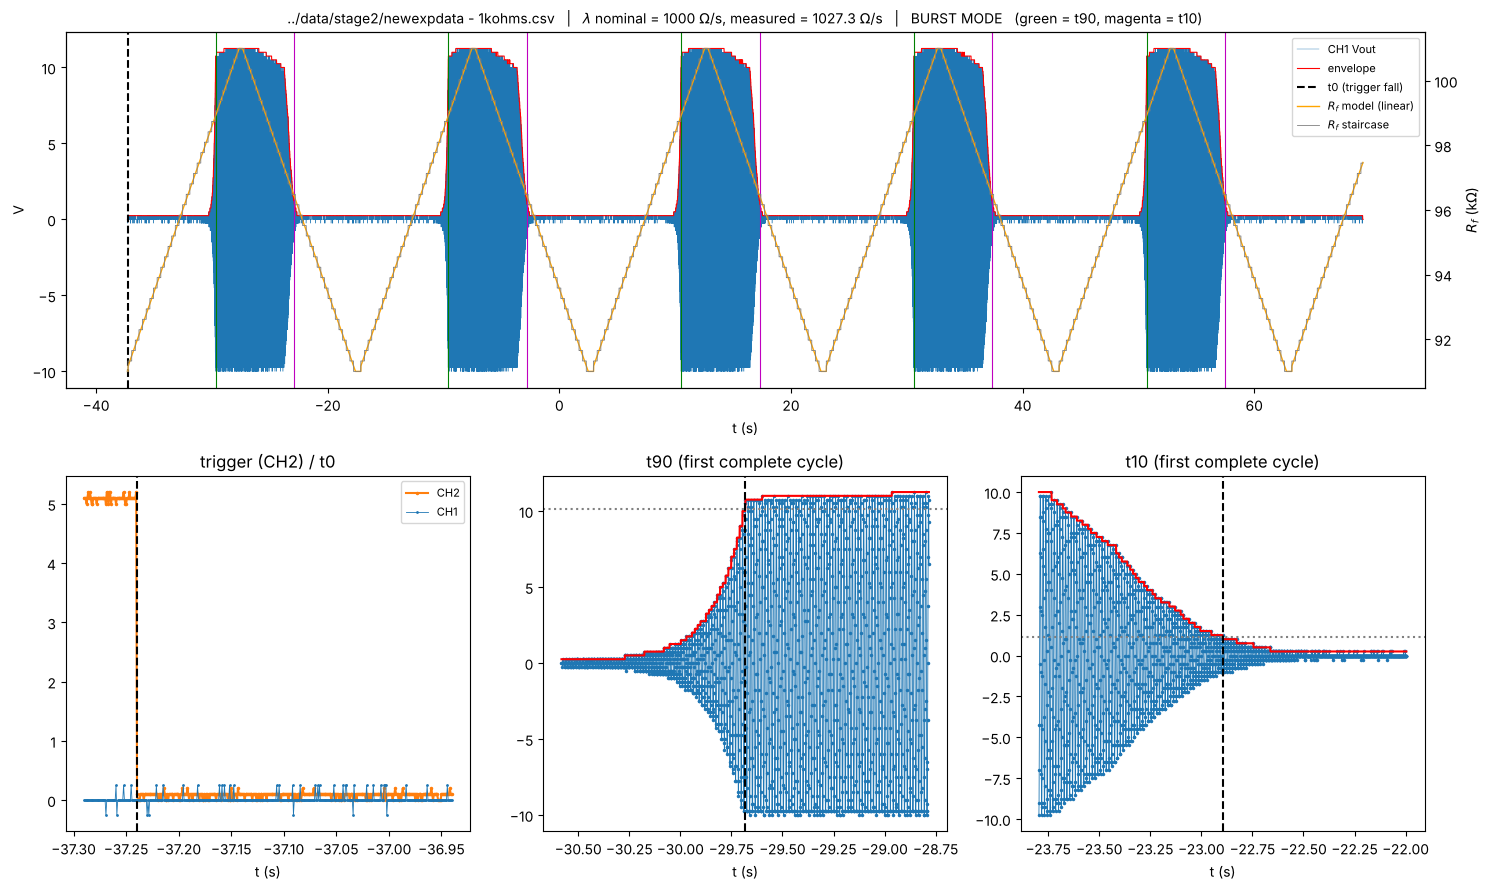

[Master] outputs/05_stage2/Masteranalysis.csv created with lambda = 1000 (5 row(s)).


In [7]:
runs = ({os.path.join(BATCH_FOLDER, f): v for f, v in BATCH_RUNS.items()} if BATCH
        else {FILE_NAME: (LAMBDA_NOMINAL, STEP_DELAY_MS)})
for path, (LAMBDA_NOMINAL, STEP_DELAY_MS) in runs.items():
    if not os.path.exists(path):
        print(f"missing: {path}"); continue
    res, info, arrays = analyse(path)
    print_report(path, res, info)
    if SHOW_CHECK_PLOT:
        check_plot(path, res, info, arrays)
    if UPDATE_MASTER and master_guard(info):
        master = update_master(build_master_rows(path, res, info))

## Check against the report

In [8]:
ref = pd.read_csv(REFERENCE_MASTER).groupby("lambda_nominal").first()
new = pd.read_csv(MASTER_CSV).groupby("lambda_nominal").first()
for lam in new.index:
    if lam not in ref.index: continue
    a, b = new.loc[lam], ref.loc[lam]
    ok = all(abs(a[c] - b[c]) < 0.5 for c in ["R_sat_mean", "R_decay_mean"]) and abs(a.lambda_measured - b.lambda_measured) < 0.01
    print(("PASS" if ok else "FAIL") + f"  lambda = {lam:g}: R_on = {a.R_sat_mean:.1f} (report {b.R_sat_mean:.1f}), "
          f"R_off = {a.R_decay_mean:.1f} (report {b.R_decay_mean:.1f}), true rate {a.lambda_measured:.1f} ohm/s (report {b.lambda_measured:.1f})")

PASS  lambda = 1000: R_on = 98925.1 (report 98925.1), R_off = 96434.9 (report 96434.9), true rate 1027.3 ohm/s (report 1027.3)


## Using your own recordings

1. Make a three-column file per run (notebook 04 does this from two oscilloscope channel files). The trigger pulse must be inside the file.
2. Set `FILE_NAME`, `LAMBDA_NOMINAL` (any label you like; it identifies the run in the master) and `STEP_DELAY_MS` (used only to sanity-check the measured sweep period and to choose cycle mode).
3. Change `R0`, `R4`, `DELTA_R`, `N_STEPS` and `STEPS_PER_HALF` if your circuit or sketch differs.
4. `ENV_WINDOW` must span several oscillation periods at your sampling interval; the report uses 0.15 s for bench data and 0.02 s for the finely sampled simulations.

Column names in the master: `R_sat_*` is the switch-on point $R_{\rm on}$ and `R_decay_*` the switch-off point $R_{\rm off}$ (names kept from the original code).